In [81]:
import pandas as pd
df = pd.read_csv("final_merge.csv")
df


,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317130,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test,10,124,31.0,F,3,107059.74,6,9
317131,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test,10,124,31.0,F,3,107059.74,6,9
317132,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test,10,124,31.0,F,3,107059.74,6,9
317133,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test,23,281,49.0,F,2,431887.61,1,4


In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   client_id         317135 non-null  int64  
 1   visitor_id        317135 non-null  str    
 2   visit_id          317135 non-null  str    
 3   process_step      317135 non-null  str    
 4   date_time         317135 non-null  str    
 5   variation         317135 non-null  str    
 6   clnt_tenure_yr    317135 non-null  int64  
 7   clnt_tenure_mnth  317135 non-null  int64  
 8   clnt_age          317135 non-null  float64
 9   gendr             317135 non-null  str    
 10  num_accts         317135 non-null  int64  
 11  bal               317135 non-null  float64
 12  calls_6_mnth      317135 non-null  int64  
 13  logons_6_mnth     317135 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 33.9 MB


In [83]:
df.isnull().sum().sum()

np.int64(0)

In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
#Changing date_time to datetime type
df["date_time"] = pd.to_datetime(df["date_time"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   client_id         317135 non-null  int64         
 1   visitor_id        317135 non-null  str           
 2   visit_id          317135 non-null  str           
 3   process_step      317135 non-null  str           
 4   date_time         317135 non-null  datetime64[us]
 5   variation         317135 non-null  str           
 6   clnt_tenure_yr    317135 non-null  int64         
 7   clnt_tenure_mnth  317135 non-null  int64         
 8   clnt_age          317135 non-null  float64       
 9   gendr             317135 non-null  str           
 10  num_accts         317135 non-null  int64         
 11  bal               317135 non-null  float64       
 12  calls_6_mnth      317135 non-null  int64         
 13  logons_6_mnth     317135 non-null  int64         
dtypes: datetime64[u

In [86]:
# Sorting for chronological order
df = df.sort_values(["visit_id", "date_time"])
df.head()

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
111630,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:22:17,Test,4,56,59.5,U,2,63130.44,6,9
111631,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:23:09,Test,4,56,59.5,U,2,63130.44,6,9
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,2,26436.73,6,9
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,2,26436.73,6,9
233387,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:21:21,Test,7,88,23.5,M,2,26436.73,6,9


In [87]:
#creating next step and next date time to set to know the correct processes and then calculate

df["next_step"] = df.groupby("visit_id")["process_step"].shift(-1)
df["next_date_time"] = df.groupby("visit_id")["date_time"].shift(-1)
df.head()

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step,next_date_time
111630,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:22:17,Test,4,56,59.5,U,2,63130.44,6,9,confirm,2017-04-26 13:23:09
111631,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:23:09,Test,4,56,59.5,U,2,63130.44,6,9,NaN,NaT
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:12
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,2,26436.73,6,9,step_2,2017-04-09 16:21:21
233387,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:21:21,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:35


In [88]:
# seconds spent between date time and next date time (one step and the next)
df["duration_sec"] = (df["next_date_time"] - df["date_time"]).dt.total_seconds()
df[["visit_id", "process_step", "date_time", "next_step", "next_date_time", "duration_sec"]]

,visit_id,process_step,date_time,next_step,next_date_time,duration_sec
111630,100012776_37918976071_457913,confirm,2017-04-26 13:22:17,confirm,2017-04-26 13:23:09,52.0
111631,100012776_37918976071_457913,confirm,2017-04-26 13:23:09,NaN,NaT,NaN
233385,100019538_17884295066_43909,start,2017-04-09 16:20:56,step_1,2017-04-09 16:21:12,16.0
233386,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,step_2,2017-04-09 16:21:21,9.0
233387,100019538_17884295066_43909,step_2,2017-04-09 16:21:21,step_1,2017-04-09 16:21:35,14.0
...,...,...,...,...,...,...
209623,999988789_76411676596_272843,start,2017-04-21 23:49:11,step_1,2017-04-21 23:49:22,11.0
209624,999988789_76411676596_272843,step_1,2017-04-21 23:49:22,step_2,2017-04-21 23:50:16,54.0
209625,999988789_76411676596_272843,step_2,2017-04-21 23:50:16,step_1,2017-04-21 23:51:00,44.0
209626,999988789_76411676596_272843,step_1,2017-04-21 23:51:00,start,2017-04-21 23:51:09,9.0


In [89]:
# We'd like to keep normal forward moves, so we need to drop the ones that are not like that

# Assigning every step a number to compare then later in a sequence
step_order = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}

df["step_number"] = df["process_step"].map(step_order)
df["next_step_number"] = df["next_step"].map(step_order)
df

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step,next_date_time,duration_sec,step_number,next_step_number
111630,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:22:17,Test,4,56,59.5,U,2,63130.44,6,9,confirm,2017-04-26 13:23:09,52.0,4,4.0
111631,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:23:09,Test,4,56,59.5,U,2,63130.44,6,9,NaN,NaT,NaN,4,NaN
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:12,16.0,0,1.0
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,2,26436.73,6,9,step_2,2017-04-09 16:21:21,9.0,1,2.0
233387,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:21:21,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:35,14.0,2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209623,6627522,730634087_44272418812,999988789_76411676596_272843,start,2017-04-21 23:49:11,Test,18,227,58.0,F,2,1056775.54,6,9,step_1,2017-04-21 23:49:22,11.0,0,1.0
209624,6627522,730634087_44272418812,999988789_76411676596_272843,step_1,2017-04-21 23:49:22,Test,18,227,58.0,F,2,1056775.54,6,9,step_2,2017-04-21 23:50:16,54.0,1,2.0
209625,6627522,730634087_44272418812,999988789_76411676596_272843,step_2,2017-04-21 23:50:16,Test,18,227,58.0,F,2,1056775.54,6,9,step_1,2017-04-21 23:51:00,44.0,2,1.0
209626,6627522,730634087_44272418812,999988789_76411676596_272843,step_1,2017-04-21 23:51:00,Test,18,227,58.0,F,2,1056775.54,6,9,start,2017-04-21 23:51:09,9.0,1,0.0


In [90]:
# Creating a column that specifies the current step to the next one (note taking into account if it is right or not)
df["step"] = df["process_step"] + " -> " + df["next_step"]
df

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step,next_date_time,duration_sec,step_number,next_step_number,step
111630,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:22:17,Test,4,56,59.5,U,2,63130.44,6,9,confirm,2017-04-26 13:23:09,52.0,4,4.0,confirm -> confirm
111631,3561384,451664975_1722933822,100012776_37918976071_457913,confirm,2017-04-26 13:23:09,Test,4,56,59.5,U,2,63130.44,6,9,NaN,NaT,NaN,4,NaN,NaN
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:12,16.0,0,1.0,start -> step_1
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,2,26436.73,6,9,step_2,2017-04-09 16:21:21,9.0,1,2.0,step_1 -> step_2
233387,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:21:21,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:35,14.0,2,1.0,step_2 -> step_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209623,6627522,730634087_44272418812,999988789_76411676596_272843,start,2017-04-21 23:49:11,Test,18,227,58.0,F,2,1056775.54,6,9,step_1,2017-04-21 23:49:22,11.0,0,1.0,start -> step_1
209624,6627522,730634087_44272418812,999988789_76411676596_272843,step_1,2017-04-21 23:49:22,Test,18,227,58.0,F,2,1056775.54,6,9,step_2,2017-04-21 23:50:16,54.0,1,2.0,step_1 -> step_2
209625,6627522,730634087_44272418812,999988789_76411676596_272843,step_2,2017-04-21 23:50:16,Test,18,227,58.0,F,2,1056775.54,6,9,step_1,2017-04-21 23:51:00,44.0,2,1.0,step_2 -> step_1
209626,6627522,730634087_44272418812,999988789_76411676596_272843,step_1,2017-04-21 23:51:00,Test,18,227,58.0,F,2,1056775.54,6,9,start,2017-04-21 23:51:09,9.0,1,0.0,step_1 -> start


In [91]:
# creating df_steps to keep only the values in which clients moved exactly one step forward to get the total of each transition
df_steps = df[df["next_step_number"] == df["step_number"] + 1]
df_steps['step'].value_counts()

step
start -> step_1      59109
step_1 -> step_2     49812
step_2 -> step_3     45448
step_3 -> confirm    33638
Name: count, dtype: int64

In [92]:
# Now checking for time outliers
#listing the 4 steps in the order of the process 
step_names = ["start -> step_1", "step_1 -> step_2", "step_2 -> step_3", "step_3 -> confirm"]

# Deciding the percentiles so we can see where the outliers are
df_steps.groupby("step")["duration_sec"].describe([0.5, 0.8, 0.99]).loc[step_names]

,count,mean,std,min,50%,80%,99%,max
step,,,,,,,,
start -> step_1,59109.0,33.915766,82.617471,0.0,13.0,37.0,375.00,3636.0
step_1 -> step_2,49812.0,35.636052,56.082130,0.0,21.0,50.0,222.00,1793.0
step_2 -> step_3,45448.0,86.737590,84.732837,0.0,66.0,121.0,426.00,1488.0
step_3 -> confirm,33638.0,114.968637,158.102775,0.0,63.0,151.0,819.63,3609.0


VISUALIZATION

<Axes: xlabel='duration_sec', ylabel='step'>

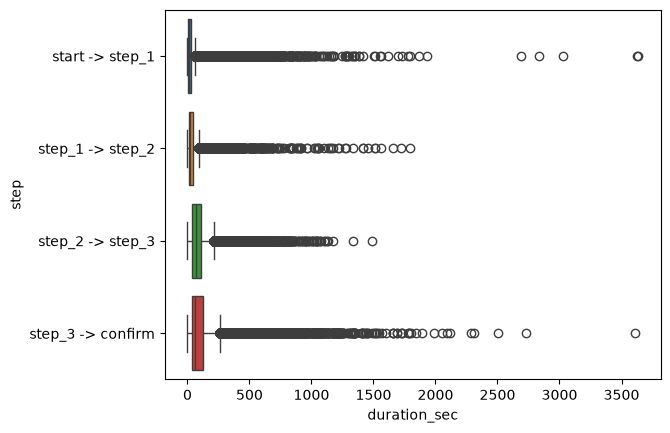

In [93]:
import seaborn as sns
sns.boxplot(data=df_steps, x="duration_sec", y="step", order=step_names, hue="step", legend=False)


In [94]:
# Removing outliers 
df_steps

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,next_step,next_date_time,duration_sec,step_number,next_step_number,step
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:21:12,16.0,0,1.0,start -> step_1
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,2,26436.73,6,9,step_2,2017-04-09 16:21:21,9.0,1,2.0,step_1 -> step_2
233391,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:21:59,Test,7,88,23.5,M,2,26436.73,6,9,step_1,2017-04-09 16:22:04,5.0,0,1.0,start -> step_1
233392,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:22:04,Test,7,88,23.5,M,2,26436.73,6,9,step_2,2017-04-09 16:22:08,4.0,1,2.0,step_1 -> step_2
233393,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:22:08,Test,7,88,23.5,M,2,26436.73,6,9,step_3,2017-04-09 16:24:01,113.0,2,3.0,step_2 -> step_3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128120,4064969,110735946_42614968419,999985675_64610694964_443659,step_1,2017-04-20 09:46:26,Control,6,75,64.5,U,2,74783.76,5,8,step_2,2017-04-20 09:47:04,38.0,1,2.0,step_1 -> step_2
128121,4064969,110735946_42614968419,999985675_64610694964_443659,step_2,2017-04-20 09:47:04,Control,6,75,64.5,U,2,74783.76,5,8,step_3,2017-04-20 09:48:45,101.0,2,3.0,step_2 -> step_3
128122,4064969,110735946_42614968419,999985675_64610694964_443659,step_3,2017-04-20 09:48:45,Control,6,75,64.5,U,2,74783.76,5,8,confirm,2017-04-20 10:02:48,843.0,3,4.0,step_3 -> confirm
209623,6627522,730634087_44272418812,999988789_76411676596_272843,start,2017-04-21 23:49:11,Test,18,227,58.0,F,2,1056775.54,6,9,step_1,2017-04-21 23:49:22,11.0,0,1.0,start -> step_1


In [95]:
# We will use until the 99 percentile of each step
df_99 = df_steps.groupby("step")["duration_sec"].quantile(0.99)
df_99

step
start -> step_1      375.00
step_1 -> step_2     222.00
step_2 -> step_3     426.00
step_3 -> confirm    819.63
Name: duration_sec, dtype: float64

In [96]:
# Matching "step" with the values of "df_99"
df_steps["df_99"] = df_steps["step"].map(df_99)

#we use df_99 to filter all the values below that and keep them

df_steps = df_steps[df_steps["duration_sec"] <= df_steps["df_99"]]
df_steps

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,...,bal,calls_6_mnth,logons_6_mnth,next_step,next_date_time,duration_sec,step_number,next_step_number,step,df_99
233385,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:20:56,Test,7,88,23.5,M,...,26436.73,6,9,step_1,2017-04-09 16:21:12,16.0,0,1.0,start -> step_1,375.0
233386,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:21:12,Test,7,88,23.5,M,...,26436.73,6,9,step_2,2017-04-09 16:21:21,9.0,1,2.0,step_1 -> step_2,222.0
233391,7338123,612065484_94198474375,100019538_17884295066_43909,start,2017-04-09 16:21:59,Test,7,88,23.5,M,...,26436.73,6,9,step_1,2017-04-09 16:22:04,5.0,0,1.0,start -> step_1,375.0
233392,7338123,612065484_94198474375,100019538_17884295066_43909,step_1,2017-04-09 16:22:04,Test,7,88,23.5,M,...,26436.73,6,9,step_2,2017-04-09 16:22:08,4.0,1,2.0,step_1 -> step_2,222.0
233393,7338123,612065484_94198474375,100019538_17884295066_43909,step_2,2017-04-09 16:22:08,Test,7,88,23.5,M,...,26436.73,6,9,step_3,2017-04-09 16:24:01,113.0,2,3.0,step_2 -> step_3,426.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128119,4064969,110735946_42614968419,999985675_64610694964_443659,start,2017-04-20 09:45:18,Control,6,75,64.5,U,...,74783.76,5,8,step_1,2017-04-20 09:46:26,68.0,0,1.0,start -> step_1,375.0
128120,4064969,110735946_42614968419,999985675_64610694964_443659,step_1,2017-04-20 09:46:26,Control,6,75,64.5,U,...,74783.76,5,8,step_2,2017-04-20 09:47:04,38.0,1,2.0,step_1 -> step_2,222.0
128121,4064969,110735946_42614968419,999985675_64610694964_443659,step_2,2017-04-20 09:47:04,Control,6,75,64.5,U,...,74783.76,5,8,step_3,2017-04-20 09:48:45,101.0,2,3.0,step_2 -> step_3,426.0
209623,6627522,730634087_44272418812,999988789_76411676596_272843,start,2017-04-21 23:49:11,Test,18,227,58.0,F,...,1056775.54,6,9,step_1,2017-04-21 23:49:22,11.0,0,1.0,start -> step_1,375.0


Text(0.5, 1.0, 'Time per step after removing outliers')

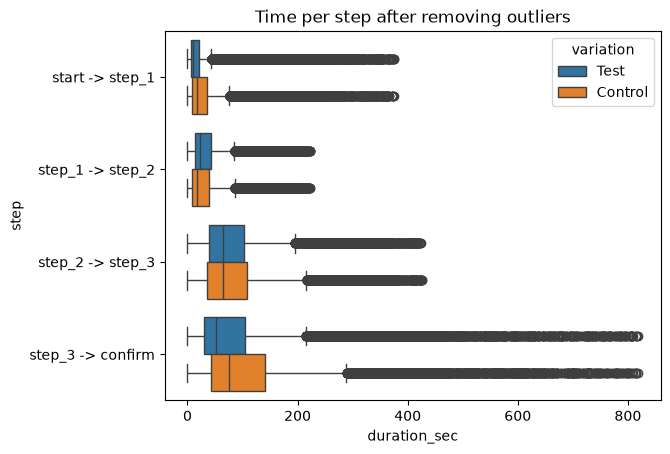

In [100]:
import matplotlib.pyplot as plt

sns.boxplot(data=df_steps, x="duration_sec", y="step", hue="variation")

plt.title("Time per step after removing outliers")

In [103]:
# Calculating the average time in seconds of each step
steps_mean = df_steps.groupby("step")["duration_sec"].mean()
steps_mean

step
start -> step_1       27.779747
step_1 -> step_2      31.763840
step_2 -> step_3      81.572276
step_3 -> confirm    104.960572
Name: duration_sec, dtype: float64

In [104]:
#storing the longest step in a variable
longest_step  = steps_mean.index[3]
longest_step

'step_3 -> confirm'

In [110]:
#Getting the mean and median per group
mean_and_median  = df_steps.groupby(['step', 'variation'])['duration_sec'].agg(["count", "mean", "median"])
mean_and_median

count        mean  median
step              variation                           
start -> step_1   Control    25456   30.876650    17.0
                  Test       33063   25.395366    10.0
step_1 -> step_2  Control    22124   30.397713    18.0
                  Test       27190   32.875432    23.0
step_2 -> step_3  Control    21053   82.098371    65.0
                  Test       23941   81.109645    65.0
step_3 -> confirm Control    15139  118.354251    75.0
                  Test       18162   93.796223    51.0

Text(0, 0.5, 'Average seconds')

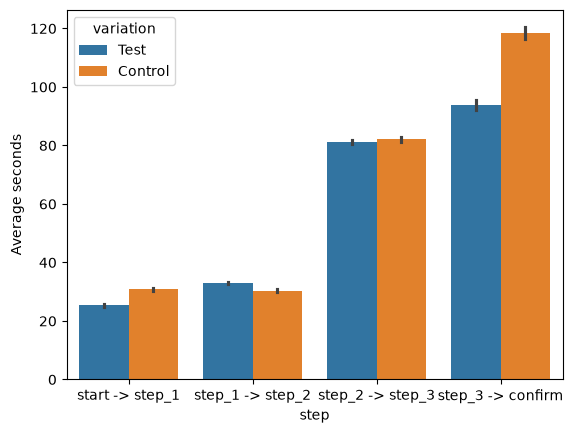

In [118]:
sns.barplot(data=df_steps, x="step", y="duration_sec", hue="variation")
plt.ylabel("Average seconds")

HYPOTHESES
H0: mu test = mu control ---- average time of a step is the same with the new UI
H1: mu test != mu control ----average time is different




In [124]:
# Making the two groups (test and control), the seconds that each visit spent on the longest step
longest_test = df_steps[(df_steps["step"] == longest_step) & (df_steps["variation"] == "Test")]["duration_sec"]
longest_control = df_steps[(df_steps["step"] == longest_step) & (df_steps["variation"] == "Control")]["duration_sec"]
display(longest_test)
display(longest_control)

233394     57.0
78008      60.0
274706     28.0
297066    152.0
48700      43.0
          ...  
301803     30.0
285215     42.0
93574      28.0
139631    163.0
26388      44.0
Name: duration_sec, Length: 18162, dtype: float64

109101      1.0
172803    327.0
30850     180.0
229584    108.0
115071     75.0
          ...  
147598     62.0
196947     81.0
114886    340.0
288723     88.0
237467     78.0
Name: duration_sec, Length: 15139, dtype: float64

In [127]:
import scipy.stats as st
alpha = 0.05
st.ttest_ind(longest_test, longest_control, equal_var=False, alternative="two-sided")

TtestResult(statistic=np.float64(-18.687358591906104), pvalue=np.float64(1.6624544110375345e-77), df=np.float64(31235.539191055243))

We reject H0, p value is below 0.05

The longest step is step 3 with an average of 105 seconds

**the other steps can be checked with the same process**